# Tutorial 2: noisy simulation (Qiskit)

<!-- BEGIN SOLUTION (remove) -->
> **This version includes the solutions.** Try each exercise yourself before reading its solution.

<!-- END SOLUTION -->
*Near-term Quantum Computing 2026-2027, tutorial 2.*

In Lecture 2, we modelled each noisy gate of a device as the ideal gate followed by a quantum
channel. Simulators describe noise in the same way: a *noise model* says which channel follows
which gate. In this tutorial, we build noise models in Qiskit, run circuits with them, and check
the predictions of Lecture 2 against the simulation.

In this tutorial you will learn to:

1. build a noise model from depolarising, relaxation and readout errors;
2. compile a circuit to the native gates of a device, so that the noise acts on the gates that run;
3. compute exact noisy expectation values with a density-matrix simulator, and compare them with
   estimates from shots.

**How this tutorial works.** As in Tutorial 1:

- **Part A** (about 40 minutes): we code together. Type the code yourself in the empty cells.
- **Part B**: exercises, alone or in pairs. Exercises 1 and 2 are the core; 3 and 4 go further.
- Questions marked **(paper)** are for pen and paper: answer them *before* running the code.

Documentation: [Qiskit API reference](https://quantum.cloud.ibm.com/docs/en/api/qiskit),
[Qiskit Aer noise module](https://qiskit.github.io/qiskit-aer/apidocs/aer_noise.html).

## Setup

In Google Colab, run the next cell first to install the packages. If you work on your own
computer, install the same packages in your Python environment instead.

In [1]:
%pip install -q "qiskit~=2.5.2" "qiskit-aer~=0.18.0" pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli
from qiskit_aer import AerSimulator

simulator = AerSimulator()

We copied here two functions from Tutorial 1: the circuit that prepares the $n$-qubit GHZ state
$\big(|0\cdots0\rangle + |1\cdots1\rangle\big)/\sqrt2$ (Exercise 4), and the estimate of a
product of $Z$ operators from counts (A4). A third function plots counts as a bar chart. Below,
we draw the 4-qubit GHZ circuit and run it without noise.

        ┌───┐                ░ ┌─┐         
   q_0: ┤ H ├──■─────────────░─┤M├─────────
        └───┘┌─┴─┐           ░ └╥┘┌─┐      
   q_1: ─────┤ X ├──■────────░──╫─┤M├──────
             └───┘┌─┴─┐      ░  ║ └╥┘┌─┐   
   q_2: ──────────┤ X ├──■───░──╫──╫─┤M├───
                  └───┘┌─┴─┐ ░  ║  ║ └╥┘┌─┐
   q_3: ───────────────┤ X ├─░──╫──╫──╫─┤M├
                       └───┘ ░  ║  ║  ║ └╥┘
meas: 4/════════════════════════╩══╩══╩══╩═
                                0  1  2  3 


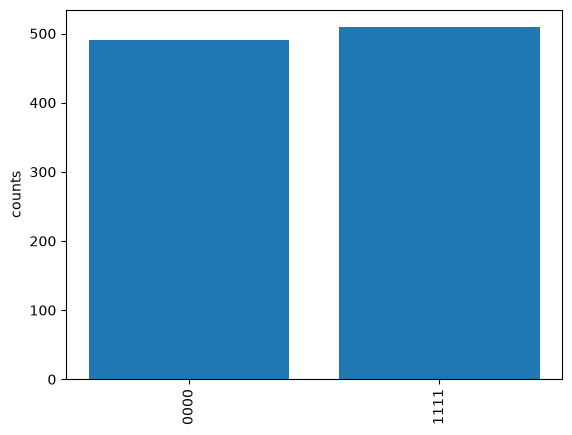

<Z0 Z1 Z2 Z3> = 1.000 ± 0.000


In [3]:
def ghz(n):
    """Circuit preparing the n-qubit GHZ state."""
    circuit = QuantumCircuit(n)
    circuit.h(0)
    for q in range(n - 1):
        circuit.cx(q, q + 1)
    return circuit


def estimate_z_product(counts, qubits):
    """Estimate <Z_q ...> over the qubits in `qubits` from a counts dictionary.

    Returns the sample mean and its standard error."""
    shots = sum(counts.values())
    total = 0
    for bitstring, n in counts.items():
        bits = bitstring[::-1]                      # now bits[q] is the outcome of qubit q
        parity = sum(int(bits[q]) for q in qubits) % 2
        total += (-1) ** parity * n
    mean = total / shots
    error = np.sqrt((1 - mean**2) / shots)
    return mean, error


def plot_counts(counts):
    """Bar chart of a counts dictionary, sorted by bitstring."""
    counts = dict(sorted(counts.items()))
    plt.bar(counts.keys(), counts.values())
    plt.xticks(rotation=90)
    plt.ylabel("counts")
    plt.show()


ghz4 = ghz(4)
ghz4_meas = ghz4.copy()
ghz4_meas.measure_all()
print(ghz4_meas.draw())

counts = simulator.run(ghz4_meas, shots=1000).result().get_counts()
plot_counts(counts)
mean, error = estimate_z_product(counts, [0, 1, 2, 3])
print(f"<Z0 Z1 Z2 Z3> = {mean:.3f} ± {error:.3f}")

## Part A: coding together

### A1. A noise model

Without noise, the GHZ circuit gives only `0000` and `1111`. To add noise, we need two things:
the channels, and a rule that says after which gates each channel acts.

**Channels.** In Qiskit Aer, a channel is a `QuantumError`. The depolarising channel of
Lecture 2, $\Lambda(\rho) = (1-p)\,\rho + p\, I/2$ on one qubit (and $I/4$ on two), is
`depolarizing_error(p, 1)` (or `depolarizing_error(p, 2)`). Qiskit stores it as a random Pauli
applied after the gate: print it to see the probability of each Pauli.

On today's devices, $p$ is about 0.1% for single-qubit gates and 0.5% for two-qubit gates. We
use values about five times larger, so that the effects are easy to see on small circuits.

In [4]:
from qiskit_aer.noise import depolarizing_error

P1 = 0.005    # single-qubit gates
P2 = 0.03     # two-qubit gates

# one_qubit_error, two_qubit_error: depolarising errors with parameters P1 and P2.
# Print one_qubit_error.
# BEGIN SOLUTION
one_qubit_error = depolarizing_error(P1, 1)
two_qubit_error = depolarizing_error(P2, 2)
print(one_qubit_error)
# END SOLUTION

QuantumError on 1 qubits. Noise circuits:
  P(0) = 0.99625, Circuit = 
   ┌───┐
q: ┤ I ├
   └───┘
  P(1) = 0.00125, Circuit = 
   ┌───┐
q: ┤ X ├
   └───┘
  P(2) = 0.00125, Circuit = 
   ┌───┐
q: ┤ Y ├
   └───┘
  P(3) = 0.00125, Circuit = 
   ┌───┐
q: ┤ Z ├
   └───┘


**Noise model.** A [`NoiseModel`](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html)
attaches errors to gates by their **names**: `add_all_qubit_quantum_error(error, ["h"])` applies
`error` after every `h` gate, on every qubit. Gates whose names do not appear in the model stay
perfect. The simulator takes the model as an argument, `AerSimulator(noise_model=...)`; the
rest (run, result, counts) works as in Tutorial 1.

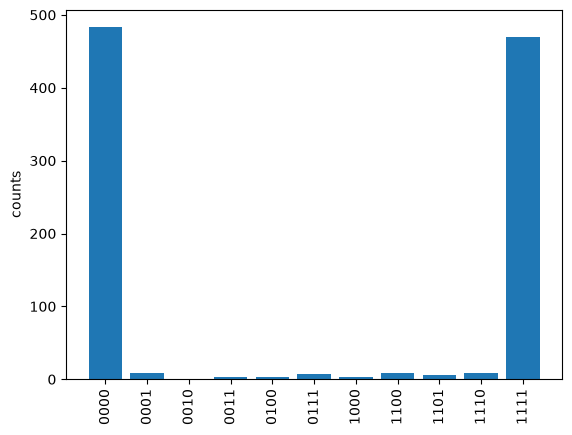

<Z0 Z1 Z2 Z3> = 0.928 ± 0.012


In [5]:
from qiskit_aer.noise import NoiseModel

# noise_model: one_qubit_error after every H gate, two_qubit_error after every CNOT (named "cx").
# Run ghz4_meas with this model for 1000 shots, plot the counts and estimate <Z0 Z1 Z2 Z3>.
# BEGIN SOLUTION
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(one_qubit_error, ["h"])
noise_model.add_all_qubit_quantum_error(two_qubit_error, ["cx"])

counts = AerSimulator(noise_model=noise_model).run(ghz4_meas, shots=1000).result().get_counts()
plot_counts(counts)
mean, error = estimate_z_product(counts, [0, 1, 2, 3])
print(f"<Z0 Z1 Z2 Z3> = {mean:.3f} ± {error:.3f}")
# END SOLUTION

Now other bitstrings appear, each a few times out of 1000: in those shots, an error occurred
somewhere in the circuit.

### A2. Native gates, and a realistic noise model

A device does not run `h` and `cx`. As we saw in Lecture 1, IQM's superconducting devices have
two native gates. The first is the phased-$X$ rotation $\mathrm{PRX}(\theta, \varphi)$, a
rotation by $\theta$ about an axis in the $xy$-plane of the Bloch sphere at angle $\varphi$ from
the $x$-axis; Qiskit calls it `r`. The second is CZ (`cz`). The error rates of a device are given
for these gates, so its noise model attaches the errors to `r` and `cz`. What happens if we run
our GHZ circuit with such a model?

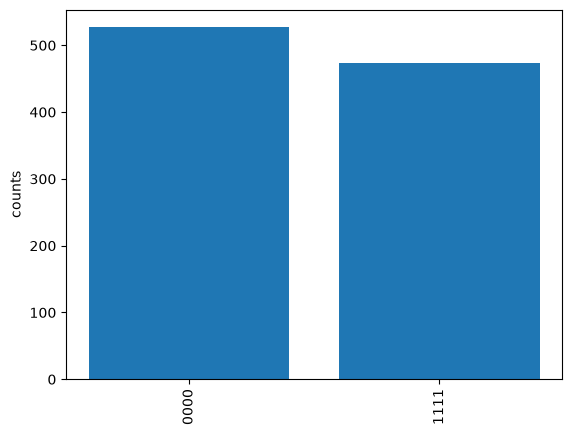

In [6]:
native_model = NoiseModel()
native_model.add_all_qubit_quantum_error(one_qubit_error, ["r"])
native_model.add_all_qubit_quantum_error(two_qubit_error, ["cz"])

# Run ghz4_meas with native_model for 1000 shots and plot the counts
# BEGIN SOLUTION
counts = AerSimulator(noise_model=native_model).run(ghz4_meas, shots=1000).result().get_counts()
plot_counts(counts)
# END SOLUTION

No errors: the circuit contains no gate named `r` or `cz`, so the model never applies. We must
first compile the circuit into native gates, as a device would. This is done by
[`transpile`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/compiler#transpile):

```python
native_circuit = transpile(circuit, basis_gates=["r", "cz"], optimization_level=0)
```

`basis_gates` lists the gates the result may use, so every other gate is rewritten in terms of
`r` and `cz`. `optimization_level=0` tells the transpiler to translate gate by gate, without
simplifying the circuit. `circuit.count_ops()` counts the gates of each kind.

global phase: 3π/2
        ┌────────────┐┌────────┐                                            »
   q_0: ┤ R(π/2,π/2) ├┤ R(π,0) ├─■──────────────────────────────────────────»
        ├────────────┤├────────┤ │ ┌────────────┐┌────────┐                 »
   q_1: ┤ R(π/2,π/2) ├┤ R(π,0) ├─■─┤ R(π/2,π/2) ├┤ R(π,0) ├─■───────────────»
        ├────────────┤├────────┤   └────────────┘└────────┘ │ ┌────────────┐»
   q_2: ┤ R(π/2,π/2) ├┤ R(π,0) ├────────────────────────────■─┤ R(π/2,π/2) ├»
        ├────────────┤├────────┤                              └────────────┘»
   q_3: ┤ R(π/2,π/2) ├┤ R(π,0) ├────────────────────────────────────────────»
        └────────────┘└────────┘                                            »
meas: 4/════════════════════════════════════════════════════════════════════»
                                                                            »
«                                              ░ ┌─┐         
«   q_0: ──────────────────────────────────────░─┤M├─────────

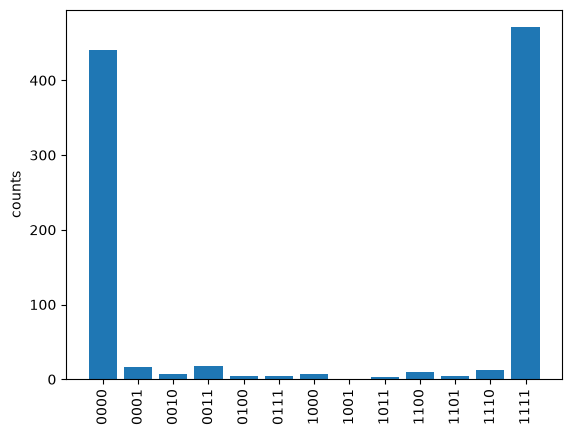

<Z0 Z1 Z2 Z3> = 0.880 ± 0.015


In [7]:
# ghz4_meas_native: ghz4_meas compiled to r and cz. Draw it, count its gates,
# run it with native_model for 1000 shots, plot the counts and estimate <Z0 Z1 Z2 Z3>.
# BEGIN SOLUTION
ghz4_meas_native = transpile(ghz4_meas, basis_gates=["r", "cz"], optimization_level=0)
print(ghz4_meas_native.draw())
print(ghz4_meas_native.count_ops())

counts = AerSimulator(noise_model=native_model).run(ghz4_meas_native, shots=1000).result().get_counts()
plot_counts(counts)
mean, error = estimate_z_product(counts, [0, 1, 2, 3])
print(f"<Z0 Z1 Z2 Z3> = {mean:.3f} ± {error:.3f}")
# END SOLUTION

**Relaxation and dephasing.** During a gate, each qubit also relaxes and dephases, as in
Lecture 2. `thermal_relaxation_error(T1, T2, t)` is this channel for a gate of duration $t$
(all three in the same units; it requires $T_2 \le 2T_1$). The errors of one gate can be
combined: `a.compose(b)` is the channel $a$ followed by $b$, and `a.tensor(b)` acts with $a$
and $b$ on two qubits at once.

Below are typical values for a superconducting device. The two gates take different times, so
they get different relaxation errors.

In [8]:
from qiskit_aer.noise import thermal_relaxation_error

T1 = 40e-6       # seconds
T2 = 10e-6
TIME_R = 20e-9   # duration of an r gate
TIME_CZ = 40e-9  # duration of a CZ

# device_model: after every r gate, one_qubit_error followed by the relaxation during the gate;
# after every CZ, two_qubit_error followed by the relaxation of both qubits during the gate.
# BEGIN SOLUTION
relax_r = thermal_relaxation_error(T1, T2, TIME_R)
relax_cz = thermal_relaxation_error(T1, T2, TIME_CZ)

device_model = NoiseModel()
device_model.add_all_qubit_quantum_error(one_qubit_error.compose(relax_r), ["r"])
device_model.add_all_qubit_quantum_error(two_qubit_error.compose(relax_cz.tensor(relax_cz)), ["cz"])
# END SOLUTION
print(device_model)

NoiseModel:
  Basis gates: ['cx', 'cz', 'id', 'r', 'rz', 'sx']
  Instructions with noise: ['r', 'cz']
  All-qubits errors: ['r', 'cz']


This model is still simplified. A qubit relaxes only during its own gates: while it waits for
the others, nothing happens to it. Real devices also add noise to waiting qubits; simulators
built from a device description, such as `AerSimulator.from_backend(...)`, include this.

### A3. Exact noisy values: the density-matrix simulator

With noise, the state of the qubits is mixed, and a state vector no longer describes it. The
density-matrix simulator, `AerSimulator(method="density_matrix")`, computes the density matrix
$\rho$ exactly, applying every channel as a map on $\rho$. This needs $4^n$ entries instead of
$2^n$, so it works only for small circuits.

In Tutorial 1, `Statevector(circuit)` computed the state directly from the circuit. This does
not work with noise: the noise model is not part of the circuit, and the simulator applies it
only while it runs. The noisy state therefore exists only inside an Aer run. To get it out, we
add the instruction `circuit.save_density_matrix()` at the end of a circuit without
measurements, which asks the run to return $\rho$:

```python
circuit.save_density_matrix()
rho = simulator.run(circuit).result().data()["density_matrix"]
```

`rho` is a [`DensityMatrix`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.DensityMatrix),
which has the same `expectation_value` method as `Statevector`, now computing
$\mathrm{Tr}[\rho P]$.

In [9]:
def noisy_density_matrix(circuit, noise_model):
    """Exact final density matrix of `circuit` (native gates, no measurements) under `noise_model`."""
    # BEGIN SOLUTION
    circuit = circuit.copy()
    circuit.save_density_matrix()
    density_simulator = AerSimulator(method="density_matrix", noise_model=noise_model)
    return density_simulator.run(circuit).result().data()["density_matrix"]
    # END SOLUTION


ghz4_native = transpile(ghz4, basis_gates=["r", "cz"], optimization_level=0)

# exact_zz: the exact noisy <Z0 Z1> of ghz4_native under device_model (ideal value: 1)
# BEGIN SOLUTION
rho = noisy_density_matrix(ghz4_native, device_model)
exact_zz = rho.expectation_value(Pauli("ZZ"), [0, 1]).real
# END SOLUTION
print("exact noisy <Z0 Z1> =", exact_zz)

exact noisy <Z0 Z1> = 0.9121348131130225


Compare with an estimate from 1000 shots, using `estimate_z_product`:

In [10]:
# mean, error: estimate of <Z0 Z1> from 1000 shots of ghz4_meas_native under device_model
# BEGIN SOLUTION
counts = AerSimulator(noise_model=device_model).run(ghz4_meas_native, shots=1000).result().get_counts()
mean, error = estimate_z_product(counts, [0, 1])
# END SOLUTION
print(f"estimate from 1000 shots: {mean:.3f} ± {error:.3f}")

estimate from 1000 shots: 0.896 ± 0.014


**Think.** The estimate scatters around the exact noisy value, not around the ideal value 1.
In Tutorial 1, $\langle Z_0 Z_1\rangle$ of a Bell state had no shot noise at all. Why is
there shot noise now, and would more shots bring the estimate closer to 1?

<!-- BEGIN SOLUTION -->
**Solution.** With noise, some shots give odd parity, so the outcomes are random again and
their variance $1 - \langle Z_0Z_1\rangle^2$ is no longer zero. More shots shrink this
statistical error, but the estimate converges to the noisy value, about 0.91, not to 1. The
difference is a *bias*, a systematic error that shots cannot remove. Exercise 3 looks at the
two errors together.
<!-- END SOLUTION -->

### Summary: from noise models to code

| Lecture 2 | Qiskit |
| --- | --- |
| depolarising channel, parameter $p$ | `depolarizing_error(p, n_qubits)` |
| relaxation and dephasing during a gate of duration $t$ | `thermal_relaxation_error(T1, T2, t)` |
| channel $a$, then channel $b$ / $a$ and $b$ on two qubits | `a.compose(b)` / `a.tensor(b)` |
| noisy gate = gate followed by a channel | `noise_model.add_all_qubit_quantum_error(error, ["gate name"])` |
| circuit in native gates | `transpile(circuit, basis_gates=["r", "cz"], optimization_level=0)` |
| samples from the noisy circuit | `AerSimulator(noise_model=...).run(circuit, shots=N)` |
| exact noisy $\rho$ | `circuit.save_density_matrix()`, then `AerSimulator(method="density_matrix", noise_model=...).run(circuit).result().data()["density_matrix"]` |
| $\mathrm{Tr}[\rho P]$ | `rho.expectation_value(Pauli("ZZ"), [0, 1])` |

## Part B: exercises

Exercises 1 and 2 are the core of this tutorial; 3 and 4 go further. Use the functions from Part A.

### Exercise 1 (core): decay and the error budget

In Lecture 2, we estimated how much signal a circuit keeps with an *error budget*: if gate $i$
goes wrong with probability $\varepsilon_i$, independently of the others, a shot runs without
any error with probability

$$
f = \prod_i (1 - \varepsilon_i).
$$

Here we test this estimate on a circuit whose ideal output we know. The *mirror circuit*
applies `ghz(n)`, then its inverse, and repeats the pair $m$ times. Ideally, it is the
identity: every shot returns $0\cdots0$. With noise, $P(0\cdots0)$ decays as $m$ grows.

**(a) (code)** Complete `mirror(n, m)`. `circuit.inverse()` returns the inverse of a circuit,
and `a.compose(b, inplace=True)` appends circuit `b` to `a`. Then compare the gate counts of
`mirror(4, 2)` transpiled to `r` and `cz` with `optimization_level=0` and with
`optimization_level=1`.

In [11]:
def mirror(n, m):
    """ghz(n) followed by its inverse, repeated m times (no measurements)."""
    # BEGIN SOLUTION
    circuit = QuantumCircuit(n)
    for _ in range(m):
        circuit.compose(ghz(n), inplace=True)
        circuit.compose(ghz(n).inverse(), inplace=True)
    return circuit
    # END SOLUTION

In [12]:
# Transpile mirror(4, 2) at levels 0 and 1; print and draw both
# BEGIN SOLUTION
c0 = transpile(mirror(4, 2), basis_gates=["r", "cz"], optimization_level=0)
print("level 0:", c0.count_ops())
print(c0.draw(fold=-1))

c1 = transpile(mirror(4, 2), basis_gates=["r", "cz"], optimization_level=1)
print("level 1:", c1.count_ops())
print(c1.draw(fold=-1))
# END SOLUTION

level 0: OrderedDict({'r': 56, 'cz': 12})
     ┌────────────┐┌────────┐                                                                                                                                                                                        ┌────────────┐┌────────┐┌────────────┐┌────────┐                                                                                                                                                                  ┌────────────┐┌────────┐
q_0: ┤ R(π/2,π/2) ├┤ R(π,0) ├─■──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────■───────┤ R(π/2,π/2) ├┤ R(π,0) ├┤ R(π/2,π/2) ├┤ R(π,0) ├─■──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────■─┤ R(π/2,π/2) ├┤ R(π,0) ├
     ├────────────┤├────────┤ │ ┌────────────┐┌────────┐      

Why must we use `optimization_level=0` here?

<!-- BEGIN SOLUTION -->
**Solution.** At level 1, the transpiler simplifies the circuit: neighbouring gates that cancel
or merge are removed, about half of them here. A compiler should do this when we want a result,
but here the noise of every gate is what we want to measure: with level 1, the circuit that
runs is no longer the one we count gates for.
<!-- END SOLUTION -->

**(b) (paper)** Use `native_model` (depolarising errors only). The printout of `one_qubit_error` in
A1 lists the probability of each Pauli. What is the probability $\varepsilon$ that a
depolarising error with parameter $p$ applies a Pauli other than the identity, on one qubit and
on two qubits? Write the budget $f$ for a circuit with $N_r$ `r` gates and $N_{cz}$ CZs.

<!-- BEGIN SOLUTION -->
**Solution.** On one qubit, $\Lambda(\rho) = (1-p)\rho + p\,I/2$ and
$I/2 = \tfrac14(\rho + X\rho X + Y\rho Y + Z\rho Z)$, so the identity has probability
$1 - 3p/4$ and $\varepsilon_1 = 3p/4$. On two qubits, $I/4$ is the average over all 16
two-qubit Paulis, so $\varepsilon_2 = 15p/16$. (The printouts show 0.99625 and 0.971875 for
the identity.) So $f = (1 - 3p_1/4)^{N_r}\,(1 - 15p_2/16)^{N_{cz}}$.
<!-- END SOLUTION -->

**(c) (code)** For $n = 2, 4, 6$ and $m = 1, \dots, 10$, compute the budget $f$ from the gate
counts, and the exact $P(0\cdots0)$ under `native_model` (`DensityMatrix.probabilities_dict()`
gives the outcome probabilities). Plot both against $m$ on a logarithmic axis.

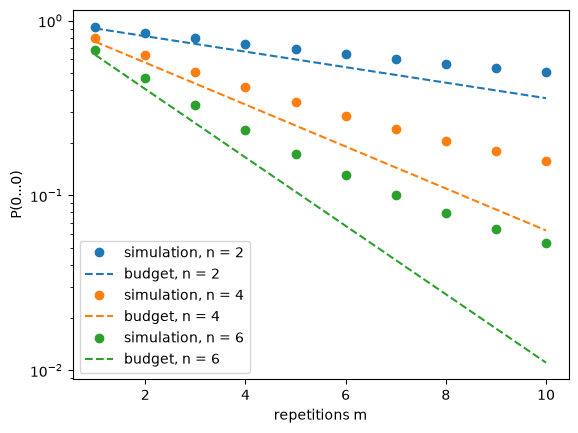

In [13]:
repetitions = range(1, 11)

for n in [2, 4, 6]:
    # budget, simulated: lists with f and the exact P(0...0), one per m
    # BEGIN SOLUTION
    budget, simulated = [], []
    for m in repetitions:
        circuit = transpile(mirror(n, m), basis_gates=["r", "cz"], optimization_level=0)
        ops = circuit.count_ops()
        budget.append((1 - 3 * P1 / 4) ** ops.get("r", 0) * (1 - 15 * P2 / 16) ** ops.get("cz", 0))
        rho = noisy_density_matrix(circuit, native_model)
        simulated.append(rho.probabilities_dict()["0" * n])
    # END SOLUTION
    line, = plt.semilogy(repetitions, simulated, "o", label=f"simulation, n = {n}")
    plt.semilogy(repetitions, budget, "--", color=line.get_color(), label=f"budget, n = {n}")

plt.xlabel("repetitions m")
plt.ylabel("P(0...0)")
plt.legend();

**(d) (paper)** The budget lies below the simulation, and more so for large $m$. Give two
reasons why a shot can return $0\cdots0$ although an error occurred.

<!-- BEGIN SOLUTION -->
**Solution.** The budget counts every error as fatal, but not every error changes the outcome.

1. Some errors do nothing to the state they act on: a $Z$ error on a qubit in $|0\rangle$
   (here, at the start and end of each mirror pair, when all qubits are in $|0\rangle$), or an
   error that a later error undoes.
2. After many errors, the output is close to random, and a random bitstring is $0\cdots0$ with
   probability $1/2^n$. So $P(0\cdots0)$ tends to $1/2^n$, not to 0. This is why the gap grows
   with $m$, and is largest for small $n$.

So the budget is a lower bound on $P(0\cdots0)$: an upper bound on the probability of an
error in the output, not an estimate of it.
<!-- END SOLUTION -->

**(e) (code)** Repeat (c) with `device_model`, which adds relaxation and dephasing, but keep
the depolarising budget. Does the budget still lie below the simulation?

Relaxation is not a Pauli channel, and its effect depends on the state it acts on. Amplitude
damping moves $|1\rangle$ towards $|0\rangle$, so it does nothing to a qubit in $|0\rangle$.
Dephasing shrinks the coherences of a superposition, so it does nothing to $|0\rangle$ or
$|1\rangle$ either. **(paper)** In which parts of the mirror circuit are the qubits in
$|0\cdots0\rangle$, and where are they in a superposition? Which of the two effects can harm
$P(0\cdots0)$, and where?

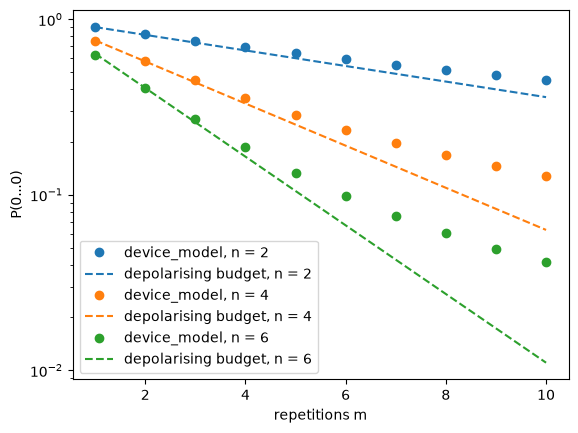

In [14]:
for n in [2, 4, 6]:
    # BEGIN SOLUTION
    budget, simulated = [], []
    for m in repetitions:
        circuit = transpile(mirror(n, m), basis_gates=["r", "cz"], optimization_level=0)
        ops = circuit.count_ops()
        budget.append((1 - 3 * P1 / 4) ** ops.get("r", 0) * (1 - 15 * P2 / 16) ** ops.get("cz", 0))
        simulated.append(noisy_density_matrix(circuit, device_model).probabilities_dict()["0" * n])
    # END SOLUTION
    line, = plt.semilogy(repetitions, simulated, "o", label=f"device_model, n = {n}")
    plt.semilogy(repetitions, budget, "--", color=line.get_color(), label=f"depolarising budget, n = {n}")

plt.xlabel("repetitions m")
plt.ylabel("P(0...0)")
plt.legend();

<!-- BEGIN SOLUTION -->
**Solution.** The simulated values drop. For small $m$ they now lie on the depolarising budget,
or slightly below it for $n = 6$: the depolarising budget no longer accounts for all the errors.

The qubits are in $|0\cdots0\rangle$ at the start and end of each mirror pair, and in a
superposition in between: the GHZ state, and the states on the way to it. Amplitude damping
cannot harm $|0\cdots0\rangle$; it acts in the middle, where some qubits are in $|1\rangle$.
Dephasing acts on the GHZ state, whose two branches the inverse circuit must recombine: a phase
error there sends the output to other bitstrings. A Pauli budget cannot see where an error
acts: it treats every error as equally harmful in every state.
<!-- END SOLUTION -->

### Exercise 2 (core): readout errors and their correction

A measurement can report the wrong bit. In Lecture 2, we described this with two error rates,
$e_0 = p(1\mid 0)$ and $e_1 = p(0\mid 1)$. They bias every expectation value: the recorded value
of $\langle Z\rangle$ is

$$
\langle Z\rangle_{\text{read}} = (1 - e_0 - e_1)\,\langle Z\rangle + (e_1 - e_0) .
$$

In Qiskit Aer, a readout error is created from its confusion matrix,
[`ReadoutError(confusion_matrix)`](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.ReadoutError.html),
with one row per true outcome and one column per recorded outcome:

$$
\begin{array}{c|cc}
 & \text{read } 0 & \text{read } 1 \\ \hline
\text{true } 0 & 1 - e_0 & e_0 \\
\text{true } 1 & e_1 & 1 - e_1
\end{array}
$$

Each row sums to 1. (This is the transpose of the matrix $M$ of Lecture 2, whose columns are the
true outcomes.) `add_all_qubit_readout_error` adds the error to every measured qubit.

**(a) (code)** Build `readout_model`, with only the readout error below. Then *calibrate* it, as
on a device: prepare $|0\rangle$ and $|1\rangle$, measure each 10 000 times, and estimate
$e_0$ and $e_1$ from the counts, with their statistical errors $\sqrt{e(1-e)/N}$.

In [15]:
from qiskit_aer.noise import ReadoutError

E0, E1 = 0.06, 0.16
CAL_SHOTS = 10_000

# readout_model: a NoiseModel with this readout error on every qubit
# e0, e1: estimates of the two error rates from CAL_SHOTS shots each
# BEGIN SOLUTION
readout_model = NoiseModel()
readout_model.add_all_qubit_readout_error(ReadoutError([[1 - E0, E0],
                                                        [E1, 1 - E1]]))
readout_simulator = AerSimulator(noise_model=readout_model)

prep0 = QuantumCircuit(1)
prep0.measure_all()
prep1 = QuantumCircuit(1)
prep1.x(0)
prep1.measure_all()
print(prep1.draw())
e0 = readout_simulator.run(prep0, shots=CAL_SHOTS).result().get_counts().get("1", 0) / CAL_SHOTS
e1 = readout_simulator.run(prep1, shots=CAL_SHOTS).result().get_counts().get("0", 0) / CAL_SHOTS
# END SOLUTION

for name, e in [("e0", e0), ("e1", e1)]:
    print(f"{name} = {e:.4f} ± {np.sqrt(e * (1 - e) / CAL_SHOTS):.4f}")

        ┌───┐ ░ ┌─┐
     q: ┤ X ├─░─┤M├
        └───┘ ░ └╥┘
meas: 1/═════════╩═
                 0 
e0 = 0.0574 ± 0.0023
e1 = 0.1603 ± 0.0037


**(b) (code)** Check the formula above on the states $R_Y(\theta)|0\rangle$ of Tutorial 1,
which have $\langle Z\rangle = \cos\theta$. Estimate $\langle Z\rangle_{\text{read}}$ from 200
shots at each angle below, and plot the estimates with error bars, together with $\cos\theta$
and the formula.

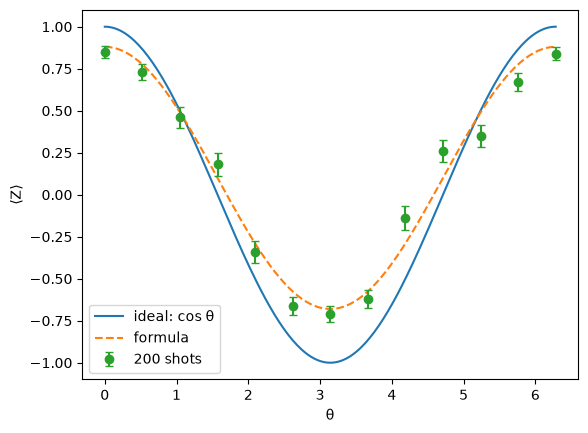

In [16]:
SHOTS = 200
angles = np.linspace(0, 2 * np.pi, 13)
fine = np.linspace(0, 2 * np.pi, 200)

# read_means, read_errors: estimate of <Z>_read and its standard error, one per angle
# BEGIN SOLUTION
read_means, read_errors = [], []
for theta in angles:
    circuit = QuantumCircuit(1)
    circuit.ry(theta, 0)
    circuit.measure_all()
    counts = readout_simulator.run(circuit, shots=SHOTS).result().get_counts()
    mean, error = estimate_z_product(counts, [0])
    read_means.append(mean)
    read_errors.append(error)
# END SOLUTION

plt.plot(fine, np.cos(fine), label="ideal: cos θ")
plt.plot(fine, (1 - E0 - E1) * np.cos(fine) + (E1 - E0), "--", label="formula")
plt.errorbar(angles, read_means, yerr=read_errors, fmt="o", capsize=3, label=f"{SHOTS} shots")
plt.xlabel("θ")
plt.ylabel("⟨Z⟩")
plt.legend();

**(c) (code)** Correct the estimates: solve the formula for $\langle Z\rangle$, using your
calibrated $e_0$ and $e_1$ from (a). Correct the error bars too, and plot the corrected
estimates with $\cos\theta$.

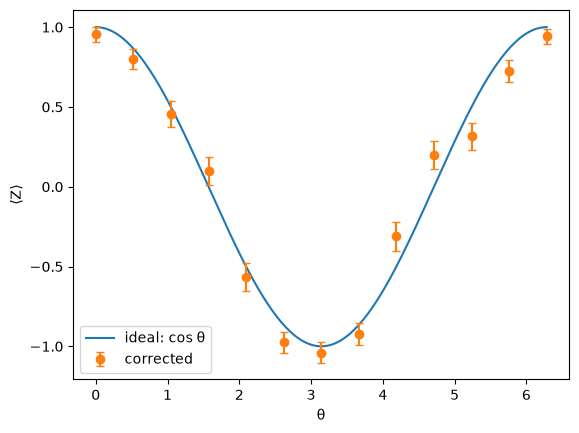

In [17]:
# corrected_means, corrected_errors: arrays, one value per angle
# BEGIN SOLUTION
scale = 1 - e0 - e1
corrected_means = (np.array(read_means) - (e1 - e0)) / scale
corrected_errors = np.array(read_errors) / scale
# END SOLUTION

plt.plot(fine, np.cos(fine), label="ideal: cos θ")
plt.errorbar(angles, corrected_means, yerr=corrected_errors, fmt="o", capsize=3, label="corrected")
plt.xlabel("θ")
plt.ylabel("⟨Z⟩")
plt.legend();

**(d) (paper)** The correction removes the bias, but the error bars grow. Why? What does the
correction cost, and what does it need to know?

<!-- BEGIN SOLUTION -->
**Solution.** Dividing by $1 - e_0 - e_1$ removes the bias, but it also divides the statistical
error by this factor, which is smaller than 1. To get back the error bars of a perfect readout,
we need $1/(1 - e_0 - e_1)^2$ times as many shots, about 1.6 here. So we trade shots for bias.
The correction also needs the error rates, measured in a calibration that costs shots of its
own and has its own statistical error. Corrected values can even fall outside $[-1, 1]$ (here near
$\theta = 0$): the correction is exact on average, not shot by shot. This is the simplest form of *error mitigation*, the
topic of a later lecture.
<!-- END SOLUTION -->

### Exercise 3 (further): bias and shot noise

With noise, an estimate from $N$ shots has two errors: the statistical error, which shrinks as
$1/\sqrt N$, and the bias, the difference between the noisy and the ideal value, which does not
shrink at all. Here we see both on one qubit.

We prepare $R_Y(\pi/3)|0\rangle$, with $\langle Z\rangle = 1/2$, and then apply $k$ pairs of
$\mathrm{PRX}(\pi, 0)$ gates: each pair is the identity, but adds noise. Under `native_model`,
each gate shrinks $\langle Z\rangle$ by $1 - p_1$.

In [18]:
def noisy_identity(k):
    """R_Y(pi/3) on one qubit, then k pairs of PRX(pi, 0) gates, in native gates."""
    circuit = QuantumCircuit(1)
    circuit.ry(np.pi / 3, 0)
    for _ in range(k):
        circuit.r(np.pi, 0, 0)
        circuit.r(np.pi, 0, 0)
    return transpile(circuit, basis_gates=["r", "cz"], optimization_level=0)


print(noisy_identity(2).draw())

   ┌────────────┐┌────────┐┌────────┐┌────────┐┌────────┐
q: ┤ R(π/3,π/2) ├┤ R(π,0) ├┤ R(π,0) ├┤ R(π,0) ├┤ R(π,0) ├
   └────────────┘└────────┘└────────┘└────────┘└────────┘


**(a) (paper)** What is the exact noisy $\langle Z\rangle$ after $k$ pairs? For $k = 10$,
compute the bias, and the number of shots $N^*$ above which the bias is larger than the
statistical error.

<!-- BEGIN SOLUTION -->
**Solution.** The circuit has $2k$ noisy PRX gates (the $R_Y$ becomes one more `r` gate,
which shrinks the value slightly too). Ignoring these, $\langle Z\rangle = f/2$ with
$f = (1 - p_1)^{2k}$; for $k = 10$, $f = 0.995^{20} \approx 0.905$, so $\langle Z\rangle \approx
0.452$ and the bias is about $-0.048$. The statistical error is
$\sqrt{(1 - \langle Z\rangle^2)/N} \approx 0.89/\sqrt N$, equal to the bias at
$N^* \approx (0.89/0.048)^2 \approx 350$ shots.
<!-- END SOLUTION -->

**(b) (code)** For $k = 10$, compute the exact noisy value with `noisy_density_matrix`, and
estimate $\langle Z\rangle$ from $N$ shots for the values of $N$ below. Plot the estimates with
error bars, together with the ideal value $1/2$ and the exact noisy value.

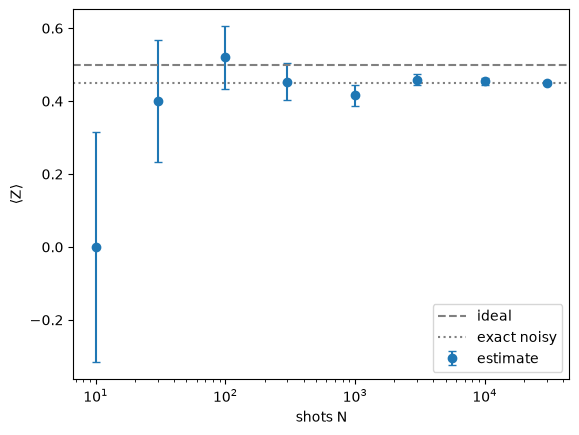

In [19]:
K = 10
shot_numbers = [10, 30, 100, 300, 1000, 3000, 10_000, 30_000]
circuit = noisy_identity(K)
circuit_meas = circuit.copy()
circuit_meas.measure_all()

# exact_noisy: exact <Z> under native_model
# means, errors: estimate of <Z> and its standard error, one per N
# BEGIN SOLUTION
exact_noisy = noisy_density_matrix(circuit, native_model).expectation_value(Pauli("Z")).real
noisy_simulator = AerSimulator(noise_model=native_model)
means, errors = [], []
for shots in shot_numbers:
    counts = noisy_simulator.run(circuit_meas, shots=shots).result().get_counts()
    mean, error = estimate_z_product(counts, [0])
    means.append(mean)
    errors.append(error)
# END SOLUTION

plt.errorbar(shot_numbers, means, yerr=errors, fmt="o", capsize=3, label="estimate")
plt.axhline(0.5, color="gray", linestyle="--", label="ideal")
plt.axhline(exact_noisy, color="gray", linestyle=":", label="exact noisy")
plt.xscale("log")
plt.xlabel("shots N")
plt.ylabel("⟨Z⟩")
plt.legend();

**(c) (paper)** Where in the plot does the bias become visible? How would the picture change for
$k = 2$, or on a device ten times less noisy? What does this mean for the number of shots worth
taking on a noisy device?

<!-- BEGIN SOLUTION -->
**Solution.** For small $N$ the error bars cover both lines; from a few hundred shots on, the
estimates cluster around the noisy value and the ideal value lies outside the error bars, as
predicted by $N^*$. With less noise ($k = 2$, or smaller $p_1$) the bias shrinks roughly in
proportion, and $N^*$ grows as one over its square: about 100 times more shots for ten times
less noise. On a noisy device, it pays to take only as many shots as make the statistical
error small compared with the bias, unless the bias is removed, for example with a correction
as in Exercise 2. The lecture notes (section "Bias and shot noise") derive the general case.
<!-- END SOLUTION -->

### Exercise 4 (further): which errors matter? The light cone

The budget of Exercise 1 counts every gate of the circuit. But an error can change the value of a
qubit only if it *reaches* that qubit before the measurement. Here we see what this means in a
bigger circuit: 8 qubits in a line.

`random_mirror(n, depth)` builds `depth` layers. Each layer applies a random `r` gate to every
qubit, then CZ gates on neighbouring pairs: $(0,1), (2,3), \dots$ in even layers and
$(1,2), (3,4), \dots$ in odd layers, a pattern called a *brickwork*. Then it applies the inverse
of all layers. As in Exercise 1, the circuit is ideally the identity, so every shot returns
$0\cdots0$, and $\langle Z_q\rangle = 1$ for every qubit $q$, as is the expectation value of any
product of $Z$s.

In [20]:
def random_mirror(n, depth, seed=1):
    """`depth` brickwork layers of random r gates and CZs on n qubits, then their inverse."""
    rng = np.random.default_rng(seed)
    layers = QuantumCircuit(n)
    for layer in range(depth):
        for q in range(n):
            layers.r(rng.uniform(0, np.pi), rng.uniform(0, 2 * np.pi), q)
        for q in range(layer % 2, n - 1, 2):
            layers.cz(q, q + 1)
    circuit = layers.copy()
    circuit.compose(layers.inverse(), inplace=True)
    return circuit


def z_on(n, qubits):
    """The Pauli operator with Z on `qubits` and I elsewhere (Qiskit reads labels right to left)."""
    label = ["I"] * n
    for q in qubits:
        label[n - 1 - q] = "Z"
    return Pauli("".join(label))


print(random_mirror(8, 1).draw(fold=-1))

      ┌──────────────────┐      ┌───────────────────┐ 
q_0: ─┤ R(1.6079,5.9719) ├─■──■─┤ R(-1.6079,5.9719) ├─
     ┌┴──────────────────┤ │  │ ├───────────────────┴┐
q_1: ┤ R(0.45289,5.9605) ├─■──■─┤ R(-0.45289,5.9605) ├
     ├───────────────────┤      ├────────────────────┤
q_2: ┤ R(0.97965,2.6598) ├─■──■─┤ R(-0.97965,2.6598) ├
     └┬──────────────────┤ │  │ ├───────────────────┬┘
q_3: ─┤ R(2.6003,2.5711) ├─■──■─┤ R(-2.6003,2.5711) ├─
     ┌┴──────────────────┤      ├───────────────────┴┐
q_4: ┤ R(1.7266,0.17316) ├─■──■─┤ R(-1.7266,0.17316) ├
     └┬──────────────────┤ │  │ ├───────────────────┬┘
q_5: ─┤ R(2.3672,3.3813) ├─■──■─┤ R(-2.3672,3.3813) ├─
      ├──────────────────┤      ├───────────────────┤ 
q_6: ─┤ R(1.0359,4.9538) ├─■──■─┤ R(-1.0359,4.9538) ├─
     ┌┴──────────────────┤ │  │ ├───────────────────┴┐
q_7: ┤ R(0.95251,2.8494) ├─■──■─┤ R(-0.95251,2.8494) ├
     └───────────────────┘      └────────────────────┘


**How errors spread.** Follow a Pauli error on one qubit through the rest of the circuit. An `r`
gate turns it into another Pauli error on the same qubit; a CZ can spread it to its partner. So
each layer spreads an error by at most one qubit on each side. The qubits an error can reach form
a *light cone*, which widens with every layer; seen from the measurement, only errors inside the
backward light cone of qubit $q$ can change $\langle Z_q\rangle$.

**(a) (paper)** Look at `random_mirror(8, 1)` above. Which gates can cause an error that changes
$\langle Z_0\rangle$? Compute the budget $f$ of these gates only, and compare it with the budget
of the whole circuit (8 `r` and 4 CZ gates per half).

<!-- BEGIN SOLUTION -->
**Solution.** With one layer, the only CZs are on the pairs $(0,1), (2,3), \dots$, so an error on
qubits 0 or 1 stays on these two qubits, and an error elsewhere never reaches qubit 0. Only the 4
`r` gates and 2 CZs on qubits 0 and 1 count:
$f_0 = (1 - 3p_1/4)^4\,(1 - 15p_2/16)^2 \approx 0.985 \times 0.944 \approx 0.93$. The whole circuit
has 16 `r` and 8 CZs, with $f \approx 0.75$.
<!-- END SOLUTION -->

**(b) (code)** For depths 1 to 8, compute under `native_model`: the budget $f$ of the whole
circuit, the exact $P(0\cdots0)$, $\langle Z_0\rangle$ (a qubit at the edge), $\langle Z_3\rangle$
(a qubit in the middle) and $\langle Z_0 Z_1 \cdots Z_7\rangle$. Use
`DensityMatrix.expectation_value(z_on(8, [...]))`. Plot all five against the depth on a
logarithmic axis.

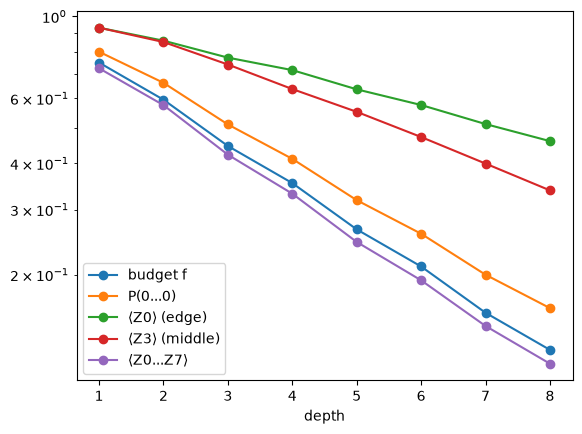

In [21]:
N_QUBITS = 8
depths = range(1, 9)
p_r, p_cz = 0.75 * P1, 15 / 16 * P2  # error probabilities from Exercise 1(b)

# results: dictionary of lists, one value per depth for each curve
results = {"budget f": [], "P(0...0)": [], "⟨Z0⟩ (edge)": [], "⟨Z3⟩ (middle)": [], "⟨Z0...Z7⟩": []}
# BEGIN SOLUTION
for depth in depths:
    circuit = transpile(random_mirror(N_QUBITS, depth), basis_gates=["r", "cz"], optimization_level=0)
    ops = circuit.count_ops()
    rho = noisy_density_matrix(circuit, native_model)
    results["budget f"].append((1 - p_r) ** ops["r"] * (1 - p_cz) ** ops["cz"])
    results["P(0...0)"].append(rho.probabilities_dict()["0" * N_QUBITS])
    results["⟨Z0⟩ (edge)"].append(rho.expectation_value(z_on(N_QUBITS, [0])).real)
    results["⟨Z3⟩ (middle)"].append(rho.expectation_value(z_on(N_QUBITS, [3])).real)
    results["⟨Z0...Z7⟩"].append(rho.expectation_value(z_on(N_QUBITS, range(N_QUBITS))).real)
# END SOLUTION

for label, values in results.items():
    plt.plot(depths, values, "o-", label=label)
plt.yscale("log")
plt.xlabel("depth")
plt.legend();

**(c) (paper)** Why do $\langle Z_0\rangle$ and $\langle Z_3\rangle$ stay far above the budget?
On the logarithmic axis, the slope of a curve is the decay per layer. Compare the slopes of
the curves, especially over the first few depths: why do $\langle Z_0\rangle$ and
$\langle Z_3\rangle$ start with the same slope, and why does that of $\langle Z_3\rangle$ then grow?
Why does the middle qubit lose its signal faster than the edge qubit? Why does
$\langle Z_0 \cdots Z_7\rangle$ follow the budget closely? Next week we estimate observables that
are sums of terms on one or two qubits: what does this plot suggest about the error budget of
such terms?

<!-- BEGIN SOLUTION -->
**Solution.** A single $\langle Z_q\rangle$ is affected only by the errors in its light cone, a
fraction of all the gates; the budget counts them all. The cone of a middle qubit can widen on
both sides, that of an edge qubit on one side only, so it contains fewer gates.

The slopes tell the same story. The budget loses the same fraction per layer at every depth (the
small zigzag comes from layers with 4 and 3 CZs), because each layer adds the same gates. At
depths 1 and 2 the cones of qubits 0 and 3 are equally small (qubits 0-1 and 2-3 at depth 1), so
the two curves coincide and are much flatter than the budget. From depth 3 on, the cone of
qubit 3 widens on both sides and contains more gates in every layer, so its slope keeps growing,
towards that of the budget; the cone of qubit 0 can widen on one side only, and its slope stays
almost constant, at less than half that of the budget.

The product of
all $Z$s is affected by (almost) every error, as $P(0\cdots0)$ is, so it follows the budget of the
whole circuit. It even lies slightly below: the budget is a lower bound on $P(0\cdots0)$ only, and
an error that flips the parity of the product counts as $-1$, not as 0.

The cones never cover the whole circuit here, even at depth 8: in a mirror, an error in the first
layers of the circuit only passes through the inverse of those layers, so it spreads little; the
same holds for errors near the end. Only errors near the middle of the circuit spread far. In a
circuit that does not undo itself, the cones keep widening, and once every cone covers all qubits,
all values decay with the same factor: the global depolarising picture of the lecture.

For terms on one or two qubits, a budget over the whole circuit is too pessimistic: count only the
gates in the light cone of the term. For shallow circuits on many qubits, this is much less.
<!-- END SOLUTION -->

## Wrap-up

- A noise model attaches channels to gates by name. Gates must be compiled to the native gates
  of the device first, otherwise the noise never applies.
- The density-matrix simulator gives exact noisy values, for small circuits; shots give
  estimates of the *noisy* value, with a bias that more shots cannot remove.
- An error budget is a quick, pessimistic estimate of the signal left. It assumes that every
  error is fatal, which holds best for small errors and for Pauli noise.
- Readout errors can be corrected if they are known, at the price of more shots.

Next week, the observables are sums of many Pauli terms, such as the energy of a physical
system, each estimated with its own shots and its own noise.